# 05-1　衝突地帶：當 $G$、$c$、$\hbar$ 同時打開

**前置**：[00-5 觀看前須知](../00_basics/05_before_quantum_gravity.ipynb)，以及前面所有單元。

這是整個課程的終點，也是 cGh 立方體裡**唯一還空著的角落**。這裡沒有一個被驗證過的理論可以拿來模擬，
所以這一課的做法是：**用已知的物理一路推到它失效的地方，看清楚到底哪裡出問題。**

1. **普朗克尺度**：三個常數能湊出的唯一長度，以及「物理的地圖」
2. **cGh 立方體**：整個課程的全景
3. **霍金輻射**：黑洞的溫度、熵、壽命（第一個同時含 $G$、$c$、$\hbar$ 的公式）
4. **資訊悖論**：Page 曲線
5. **真空能量**：差了 $10^{120}$ 倍的預測
6. **疊加態物質的引力**：半古典重力的模擬，以及 1981 年的實驗
7. **時間問題**，以及候選理論
8. **回到最初的問題**：兩套理論互相揭露了什麼

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

plt.rcParams["font.family"] = ["Microsoft JhengHei", "sans-serif"]  # 中文標籤
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 100

G, c, hbar, k_B = 6.674_30e-11, 2.997_924_58e8, 1.054_571_817e-34, 1.380_649e-23
M_sun = 1.989e30
year = 3.156e7
AGE_UNIVERSE = 13.8e9 * year


def log_formatter(ax, axis="both"):
    # 對數刻度改用「1e-35」這種寫法（避開數學字型缺負號）
    f = plt.FuncFormatter(lambda v, _: f"1e{np.log10(v):.0f}")
    if axis in ("x", "both"):
        ax.xaxis.set_major_formatter(f)
        ax.xaxis.set_minor_formatter(plt.NullFormatter())
    if axis in ("y", "both"):
        ax.yaxis.set_major_formatter(f)
        ax.yaxis.set_minor_formatter(plt.NullFormatter())

## 1. 普朗克尺度

用 00-5 第 1 章的因次分析：**$G$、$c$、$\hbar$ 三個常數，能湊出什麼長度、時間、質量？**

| 常數 | 單位 | 代表 |
|---|---|---|
| $G$ | m³ kg⁻¹ s⁻² | 重力（廣義相對論） |
| $c$ | m s⁻¹ | 相對論 |
| $\hbar$ | m² kg s⁻¹ | 量子力學 |

In [2]:
# 單位寫成 [公尺, 公斤, 秒] 的次方；每一欄是 G、c、ħ
A = np.array([[3, 1, 2],
              [-1, 0, 1],
              [-2, -1, -1]])
constants = np.array([G, c, hbar])

planck = {}
for name, target, unit in [("長度", [1, 0, 0], "m"), ("時間", [0, 0, 1], "s"), ("質量", [0, 1, 0], "kg")]:
    a, b, d = np.linalg.solve(A, target)
    value = G**a * c**b * hbar**d
    planck[name] = value
    print(f"普朗克{name} = G^({a:+.1f}) c^({b:+.1f}) ħ^({d:+.1f}) = {value:.3e} {unit}")

l_P, t_P, m_P = planck["長度"], planck["時間"], planck["質量"]
E_P = m_P * c**2
print(f"\n普朗克能量 = {E_P:.2e} J = {E_P / 1.602e-10:.2e} GeV（LHC 的碰撞能量約 1.4e4 GeV）")
print(f"普朗克溫度 = {E_P / k_B:.2e} K")

普朗克長度 = G^(+0.5) c^(-1.5) ħ^(+0.5) = 1.616e-35 m
普朗克時間 = G^(+0.5) c^(-2.5) ħ^(+0.5) = 5.391e-44 s
普朗克質量 = G^(-0.5) c^(+0.5) ħ^(+0.5) = 2.176e-08 kg

普朗克能量 = 1.96e+09 J = 1.22e+19 GeV（LHC 的碰撞能量約 1.4e4 GeV）
普朗克溫度 = 1.42e+32 K


得到 $\ell_P = \sqrt{\hbar G/c^3} \approx 1.6\times10^{-35}$ m、$t_P \approx 5.4\times10^{-44}$ s、$m_P \approx 2.2\times10^{-8}$ kg。

**為什麼這是量子重力的尺度？** 對一個質量 $m$ 的東西，兩種理論各自給出一個「大小」：

- **量子力學**：康普頓波長 $\lambda_C = \hbar / mc$。想把它定位得比這更準，能量就足以產生新的粒子，「單一粒子」的概念就失效了。
- **廣義相對論**：史瓦西半徑 $r_s = 2Gm/c^2$。比這更小，它就是黑洞。

**兩者相等的地方，就是普朗克質量。** 畫成一張圖：

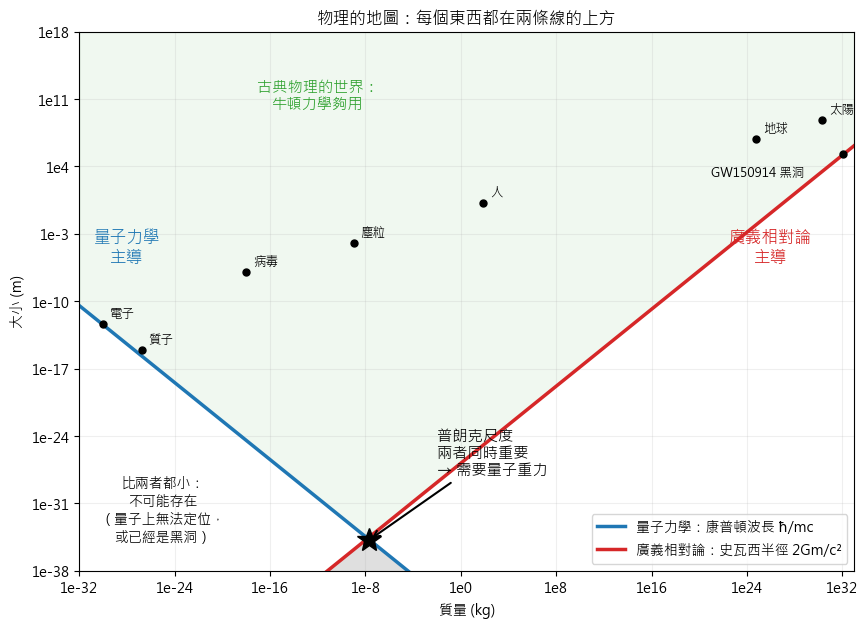

In [3]:
m = np.logspace(-32, 33, 400)
lam_C = hbar / (m * c)
r_s = 2 * G * m / c**2

objects = [("電子", 9.11e-31, 3.9e-13), ("質子", 1.67e-27, 8.4e-16), ("病毒", 1e-18, 1e-7),
           ("塵粒", 1e-9, 1e-4), ("人", 70, 1.7), ("地球", 5.97e24, 6.37e6), ("太陽", M_sun, 6.96e8),
           ("GW150914 黑洞", 62 * M_sun, 2 * G * 62 * M_sun / c**2)]

fig, ax = plt.subplots(figsize=(10, 7))
ax.loglog(m, lam_C, "C0", lw=2.5, label="量子力學：康普頓波長 ħ/mc")
ax.loglog(m, r_s, "C3", lw=2.5, label="廣義相對論：史瓦西半徑 2Gm/c²")
ax.fill_between(m, 1e-40, np.minimum(lam_C, r_s), color="gray", alpha=0.25)
ax.fill_between(m, np.maximum(lam_C, r_s), 1e30, color="C2", alpha=0.07)
ax.text(1e-25, 1e-35, "比兩者都小：\n不可能存在\n（量子上無法定位，\n或已經是黑洞）", fontsize=10, ha="center")
ax.text(1e-12, 1e10, "古典物理的世界：\n牛頓力學夠用", fontsize=11, ha="center", color="C2")
ax.text(1e-28, 1e-6, "量子力學\n主導", color="C0", fontsize=12, ha="center")
ax.text(1e26, 1e-6, "廣義相對論\n主導", color="C3", fontsize=12, ha="center")
ax.plot(m_P, l_P, "k*", ms=18)
ax.annotate("普朗克尺度\n兩者同時重要\n→ 需要量子重力", (m_P, l_P), (1e-2, 1e-28), fontsize=11,
            arrowprops=dict(arrowstyle="->", lw=1.5))
for name, mass, size in objects:
    ax.plot(mass, size, "ko", ms=5)
    offset = (-95, -16) if "GW" in name else (5, 5)
    ax.annotate(name, (mass, size), offset, textcoords="offset points", fontsize=9)
ax.set_xlim(1e-32, 1e33)
ax.set_ylim(1e-38, 1e18)
ax.set_xlabel("質量 (kg)")
ax.set_ylabel("大小 (m)")
ax.set_title("物理的地圖：每個東西都在兩條線的上方")
ax.legend(loc="lower right", fontsize=10)
log_formatter(ax)
ax.grid(alpha=0.2)
plt.show()

**觀察**：

- 所有真實的東西都在兩條線**上方**：電子靠近藍線（量子），黑洞剛好在紅線上（廣義相對論），中間的一切都是古典物理的領域。
- 兩條線在**普朗克尺度**交叉。那裡一個東西**同時**是量子的、又是黑洞。目前沒有理論能描述那裡。
- **最小長度**：想看清楚比 $\ell_P$ 更小的東西，需要波長更短的探針（量子力學），也就是能量更高（$E = hc/\lambda$）。
  但能量太集中又會形成黑洞（廣義相對論），黑洞會把你想看的東西吞掉。**兩個理論合起來，暗示空間可能有最小的尺度。**
- 黑洞中心的奇異點（04-1 實驗 2）、大爆炸的起點，都會掉進這個灰色區域。

## 2. cGh 立方體：整個課程的全景

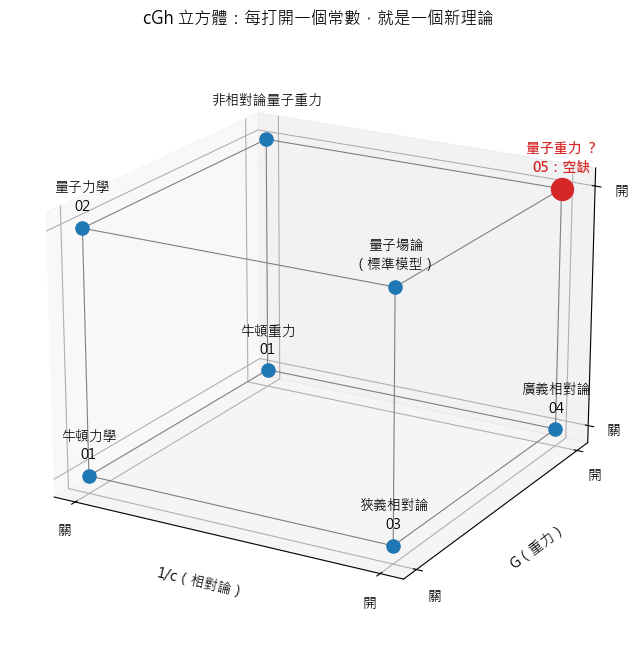

In [4]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

corners = {
    (0, 0, 0): ("牛頓力學", "01"),
    (1, 0, 0): ("狹義相對論", "03"),
    (0, 0, 1): ("量子力學", "02"),
    (0, 1, 0): ("牛頓重力", "01"),
    (1, 1, 0): ("廣義相對論", "04"),
    (1, 0, 1): ("量子場論", "（標準模型）"),
    (0, 1, 1): ("非相對論量子重力", ""),
    (1, 1, 1): ("量子重力 ？", "05：空缺"),
}
fig = plt.figure(figsize=(8.5, 8))
ax = fig.add_subplot(projection="3d")
for a_ in (0, 1):
    for b_ in (0, 1):
        ax.plot([0, 1], [a_, a_], [b_, b_], "gray", lw=0.8)
        ax.plot([a_, a_], [0, 1], [b_, b_], "gray", lw=0.8)
        ax.plot([a_, a_], [b_, b_], [0, 1], "gray", lw=0.8)
for (x, y, z), (name, unit) in corners.items():
    final = (x, y, z) == (1, 1, 1)
    ax.scatter(x, y, z, s=250 if final else 90, c="C3" if final else "C0", depthshade=False)
    ax.text(x, y, z + 0.07, f"{name}\n{unit}", fontsize=10, ha="center", weight="bold" if final else "normal",
            color="C3" if final else "k")
ax.set_xlabel("1/c（相對論）")
ax.set_ylabel("G（重力）")
ax.set_zlabel("ħ（量子）")
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_zticks([0, 1])
ax.set_xticklabels(["關", "開"])
ax.set_yticklabels(["關", "開"])
ax.set_zticklabels(["關", "開"])
ax.view_init(elev=20, azim=-60)
ax.set_title("cGh 立方體：每打開一個常數，就是一個新理論")
plt.show()

我們從原點（牛頓）出發，沿著三條邊走過量子力學（02）、狹義相對論（03）、廣義相對論（04）。
**只有對角那一個角，三個常數全開，還沒有被驗證的理論。** 接下來的每一節，都是站在這個角落的邊緣往裡面看。

## 3. 霍金輻射：黑洞不是全黑的

1974 年，霍金把**量子場論**放在**黑洞的彎曲時空**上計算（這叫「半古典」：物質是量子的，時空是古典的）。結果驚人：**黑洞會發出黑體輻射**（00-5 第 3 章），溫度是

$$T_H = \frac{\hbar c^3}{8\pi G M k_B}$$

**這是物理學史上第一個同時含有 $\hbar$、$c$、$G$、$k_B$ 的公式**，量子力學、相對論、重力、熱力學全部到齊。

同時，黑洞有**熵**（貝肯斯坦–霍金熵），正比於視界的**面積** $A = 4\pi r_s^2$：

$$S = \frac{k_B c^3 A}{4G\hbar} = k_B\,\frac{A}{4\ell_P^2}$$

用位元來數（00-5 第 4 章）：**視界上每 4 個普朗克面積，存 1/ln2 個位元**。

黑洞會一直輻射、一直變輕、越輕越熱，最後**蒸發**掉。壽命是

$$t_{\text{蒸發}} = \frac{5120\pi G^2 M^3}{\hbar c^4}$$

In [5]:
def hawking(M):
    T = hbar * c**3 / (8 * np.pi * G * M * k_B)
    rs = 2 * G * M / c**2
    S_bits = (4 * np.pi * rs**2) / (4 * l_P**2) / np.log(2)
    t_evap = 5120 * np.pi * G**2 * M**3 / (hbar * c**4)
    return rs, T, S_bits, t_evap


def fmt_time(s):
    if s < 1:
        return f"{s:.1e} 秒"
    if s < year:
        return f"{s:.1f} 秒"
    return f"{s / year:.1e} 年"


cases = [("GW150914 合併後（62 M☉）", 62 * M_sun), ("太陽質量", M_sun), ("地球質量", 5.97e24),
         ("月球質量", 7.35e22), ("一座山（1e12 kg）", 1e12), ("1 公噸", 1e3)]
print(f"{'黑洞':<22}{'史瓦西半徑':>12}{'溫度 (K)':>12}{'熵（位元）':>12}{'壽命':>16}")
for name, M in cases:
    rs, T, S, t = hawking(M)
    rs_str = f"{rs / 1000:.1f} km" if rs > 1000 else (f"{rs * 1000:.2f} mm" if rs > 1e-6 else f"{rs:.1e} m")
    print(f"{name:<20}{rs_str:>12}{T:>12.2e}{S:>12.1e}{fmt_time(t):>16}")

print(f"\n宇宙年齡：{AGE_UNIVERSE / year:.1e} 年；宇宙微波背景溫度：2.725 K")
M_equal = hbar * c**3 / (8 * np.pi * G * 2.725 * k_B)
M_age = (AGE_UNIVERSE * hbar * c**4 / (5120 * np.pi * G**2)) ** (1 / 3)
print(f"溫度剛好等於宇宙背景的黑洞：{M_equal:.1e} kg（約月球質量），比它重的黑洞吸收比放出多")
print(f"壽命剛好等於宇宙年齡的黑洞：{M_age:.1e} kg（只算光子的簡化公式）")

黑洞                           史瓦西半徑      溫度 (K)       熵（位元）              壽命
GW150914 合併後（62 M☉）     183.2 km    9.95e-10     5.8e+80       5.0e+72 年
太陽質量                      3.0 km    6.17e-08     1.5e+77       2.1e+67 年
地球質量                     8.87 mm    2.06e-02     1.4e+66       5.7e+50 年
月球質量                     0.11 mm    1.67e+00     2.1e+62       1.1e+45 年
一座山（1e12 kg）           1.5e-15 m    1.23e+11     3.8e+40       2.7e+12 年
1 公噸                   1.5e-24 m    1.23e+20     3.8e+22       8.4e-08 秒

宇宙年齡：1.4e+10 年；宇宙微波背景溫度：2.725 K
溫度剛好等於宇宙背景的黑洞：4.5e+22 kg（約月球質量），比它重的黑洞吸收比放出多
壽命剛好等於宇宙年齡的黑洞：1.7e+11 kg（只算光子的簡化公式）


**觀察**：

- **太陽質量的黑洞**：溫度 $6\times10^{-8}$ K，比宇宙背景還冷，壽命 $10^{67}$ 年，遠遠超過宇宙年齡（$10^{10}$ 年）。霍金輻射小到完全量不到。
- **一座山那麼重的黑洞**（$10^{12}$ kg，比原子核還小）：溫度上千億度，壽命約 3 兆年。再輕一點、約 $1.7	imes10^{11}$ kg 的黑洞，壽命**剛好等於宇宙年齡**。如果宇宙早期產生過這種「原初黑洞」，現在應該正在爆炸性地蒸發。天文學家找過，還沒找到。
- **熵大得驚人**：太陽質量黑洞的熵約 $10^{77}$ 位元，比太陽本身的熵（約 $10^{58}$）大了約 $10^{19}$ 倍。黑洞是宇宙中最有效率的「資訊儲存」。

**熵正比於面積而不是體積**，非常奇怪。一般東西（一箱氣體）的熵正比於體積。這暗示**三維空間裡的資訊，好像可以寫在二維的邊界上**，叫「**全像原理**」，是量子重力研究最重要的線索之一。

## 4. 資訊悖論：Page 曲線

**問題**：把一本書丟進黑洞，黑洞蒸發後只剩熱輻射。熱輻射是**完全隨機**的，只由溫度決定，不帶書裡的任何資訊。
**資訊消失了**，這違反量子力學的么正性（02-1 實驗 4：時間演化永遠可以倒轉）。

**用熵來看**：把「黑洞 + 輻射」當成一個整體，它一開始是一個純粹的量子態（熵 = 0）。
如果資訊守恆，**輻射的熵（對外面的人來說）不能超過剩下的黑洞的熵**，因為輻射和黑洞糾纏在一起，兩邊的「不確定」是同一份。

- **霍金的計算**：輻射的熵一直增加，直到黑洞消失
- **資訊守恆的要求（Page，1993）**：輻射的熵先增加，到一半時必須**轉頭往下**，最後回到 0

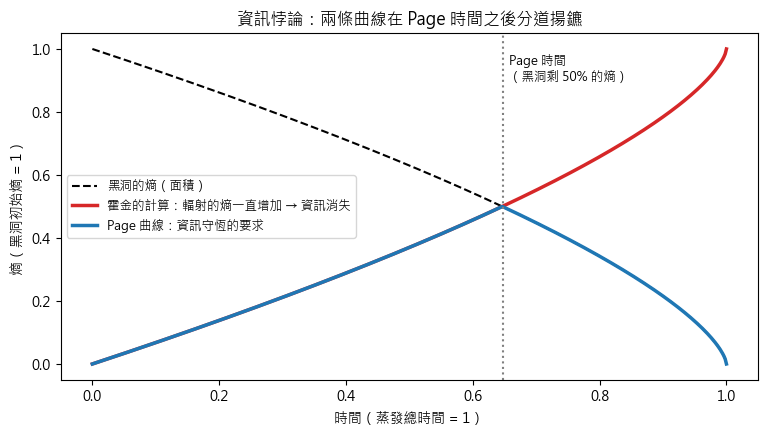

In [6]:
tau = np.linspace(0, 1, 500)              # 時間 / 蒸發總時間
M_frac = (1 - tau) ** (1 / 3)             # 黑洞質量 M(t) ∝ (1 − t/t_evap)^(1/3)
S_bh = M_frac**2                          # 黑洞的熵 ∝ M²（以初始熵為 1）
S_hawking = 1 - S_bh                      # 霍金：輻射帶走的熵一直累積
S_page = np.minimum(S_hawking, S_bh)      # 資訊守恆：輻射的熵不能超過黑洞剩下的

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(tau, S_bh, "k--", label="黑洞的熵（面積）")
ax.plot(tau, S_hawking, "C3", lw=2.5, label="霍金的計算：輻射的熵一直增加 → 資訊消失")
ax.plot(tau, S_page, "C0", lw=2.5, label="Page 曲線：資訊守恆的要求")
t_page = tau[np.argmax(S_page)]
ax.axvline(t_page, color="gray", ls=":")
ax.text(t_page + 0.01, 0.9, f"Page 時間\n（黑洞剩 {S_bh[np.argmax(S_page)]:.0%} 的熵）", fontsize=9)
ax.set_xlabel("時間（蒸發總時間 = 1）")
ax.set_ylabel("熵（黑洞初始熵 = 1）")
ax.set_title("資訊悖論：兩條曲線在 Page 時間之後分道揚鑣")
ax.legend(loc="center left", fontsize=9)
plt.show()

**紅線和藍線的差別，就是資訊悖論。** 霍金的半古典計算給出紅線，量子力學的么正性要求藍線。

這個問題吵了將近 50 年。**2019 年**，幾組物理學家（Penington；Almheiri、Engelhardt、Marolf、Maxfield 等人）在一些簡化的模型裡，
考慮了時空幾何本身的量子效應（叫「**島嶼**」），成功算出了藍線。目前大多數人相信**資訊沒有消失**，
但它到底**怎麼**跑出黑洞，在真實的四維時空裡還沒有完整答案。

**這是量子力學「贏了」的地方**：它的么正性逼著廣義相對論的黑洞圖像必須修改。

## 5. 真空能量：物理史上最糟的預測

00-5 第 5 章：真空中的每一個場，可以拆成無數個振子，每個都有零點能量 $\frac12\hbar\omega$。

把**一個場**（例如電磁場，2 個偏振方向）在每立方公尺裡、波數小於 $k_{\max}$ 的所有振子加起來：

$$\rho_{\text{真空}} = 2\times\int_0^{k_{\max}}\frac12\hbar c k\cdot\frac{4\pi k^2\,dk}{(2\pi)^3} = \frac{\hbar c\,k_{\max}^4}{8\pi^2}$$

**沒有上限的話，這是無限大**（$k^4$ 一直變大）。在其他三種力的物理裡，這不是問題：只有能量**差**能被量到，零點可以隨便設。

**但重力不一樣**：愛因斯坦方程式的右邊是**所有**能量，包括零點能量。真空能量會讓宇宙加速膨脹，所以我們可以從宇宙的膨脹量出它。

In [7]:
H0 = 67.7e3 / 3.086e22            # 哈伯常數 (1/s)
Omega_L = 0.69
rho_crit = 3 * H0**2 / (8 * np.pi * G)
rho_dark_energy = Omega_L * rho_crit * c**2       # 觀測到的暗能量密度 (J/m³)


def vacuum_energy(k_max):
    return hbar * c * k_max**4 / (8 * np.pi**2)


print(f"觀測到的暗能量密度：{rho_dark_energy:.1e} J/m³（約等於每立方公尺 {rho_dark_energy / c**2 / 1.67e-27:.0f} 個氫原子的質量）\n")
print(f"{'截斷在哪裡':<36}{'k_max (1/m)':>12}{'預測 (J/m³)':>14}{'預測 / 觀測':>14}")
for name, k_max in [("普朗克尺度（物理理論的極限）", 1 / l_P),
                    ("LHC 已經驗證過的能量（約 10 TeV）", 1e4 * 1.602e-10 / (hbar * c)),
                    ("電子的康普頓波長", 1 / (hbar / (9.11e-31 * c)))]:
    rho = vacuum_energy(k_max)
    print(f"{name:<32}{k_max:>12.1e}{rho:>14.1e}{rho / rho_dark_energy:>14.0e}")

觀測到的暗能量密度：5.3e-10 J/m³（約等於每立方公尺 4 個氫原子的質量）

截斷在哪裡                                k_max (1/m)     預測 (J/m³)       預測 / 觀測
普朗克尺度（物理理論的極限）                       6.2e+34      5.9e+111        1e+121
LHC 已經驗證過的能量（約 10 TeV）               5.1e+19       2.6e+51         5e+60
電子的康普頓波長                             2.6e+12       1.8e+22         3e+31


**截斷在普朗克尺度，預測值比觀測大了大約 $10^{121}$ 倍**（常被說成「$10^{120}$」，依算法不同落在 $10^{120}$ 到 $10^{123}$ 之間）。
就算只算到人類已經用加速器驗證過的能量，也還差了 $10^{60}$ 倍。

**這是我們最早討論的第 3 點**：量子場論說「零點可以忽略」，但重力看得到所有能量。
這個數字如果真的那麼大，宇宙在誕生的一瞬間就會被撕碎，不會有星系、更不會有我們。

某種機制讓真空能量幾乎完全抵消，卻又剩下一點點（剛好是暗能量），沒有人知道為什麼。這叫**宇宙學常數問題**。

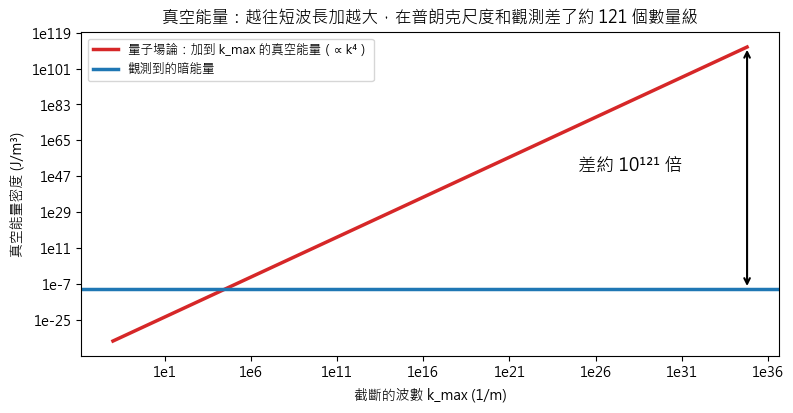

In [8]:
k = np.logspace(-2, np.log10(1 / l_P), 300)
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.loglog(k, vacuum_energy(k), "C3", lw=2.5, label="量子場論：加到 k_max 的真空能量（∝ k⁴）")
ax.axhline(rho_dark_energy, color="C0", lw=2.5, label="觀測到的暗能量")
ax.annotate("", xy=(1 / l_P, rho_dark_energy), xytext=(1 / l_P, vacuum_energy(1 / l_P)),
            arrowprops=dict(arrowstyle="<->", lw=1.5))
ax.text(1e25, 1e50, "差約 10¹²¹ 倍", fontsize=13)
ax.set_xlabel("截斷的波數 k_max (1/m)")
ax.set_ylabel("真空能量密度 (J/m³)")
ax.set_title("真空能量：越往短波長加越大，在普朗克尺度和觀測差了約 121 個數量級")
log_formatter(ax)
ax.legend(loc="upper left", fontsize=9)
plt.show()

## 6. 疊加態物質的引力：半古典重力會怎樣？

這是我們最早討論的第 3 點的核心：**愛因斯坦方程式的右邊放不進量子物質。**

最直接的折衷叫**半古典重力**：把右邊換成量子期望值

$$G_{\mu\nu} = \frac{8\pi G}{c^4}\,\langle T_{\mu\nu}\rangle$$

霍金輻射就是用這個方法算的。它在大多數情況下很好用，但遇到 00-5 第 6 章的「平均值陷阱」就出問題了。

**模擬**：一顆大質量的球處在「50% 在左邊、50% 在右邊」的疊加態。正上方有一顆小測試粒子，從靜止開始被吸引。

- **半古典重力**：引力來自 $\langle\rho\rangle$，也就是「左邊半顆 + 右邊半顆」。測試粒子會**直直往下**，掉向兩者中間。
- **如果重力看到的是真實位置**（量子態在某個時刻「塌縮」到其中一邊）：測試粒子會被拉向**左邊或右邊**，各 50%。

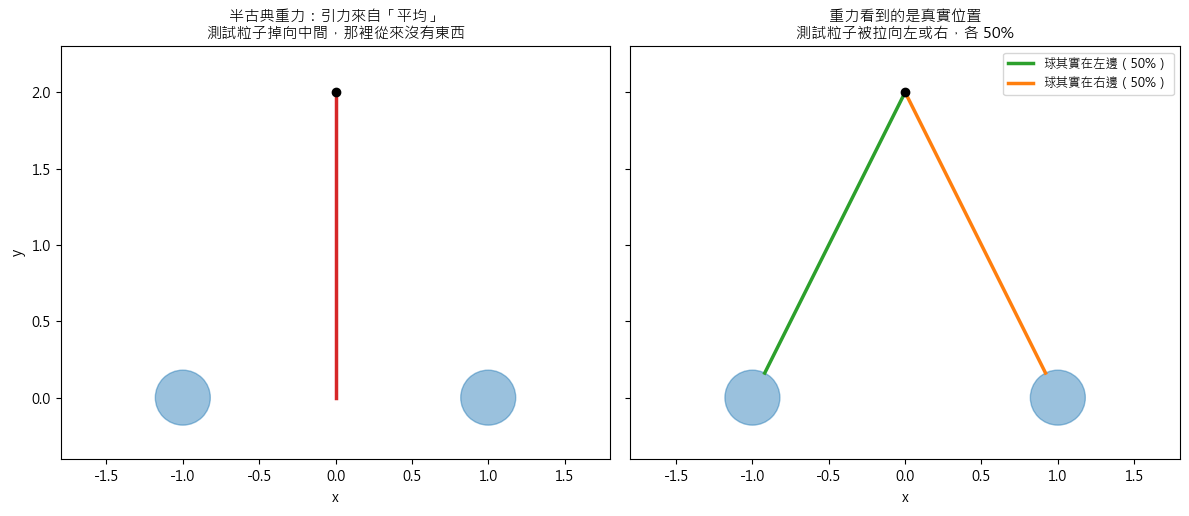

In [9]:
GM_big = 1.0                    # 自然單位
d = 1.0                         # 球在 x = ±d
start = np.array([0.0, 2.0])    # 測試粒子的起點（正上方）


def fall(sources, t_end=10.0):
    # sources: [(x 位置, 質量比例)...]；回傳測試粒子的軌跡
    def rhs(t, s):
        x, y, vx, vy = s
        ax_ = ay_ = 0.0
        for xs, w in sources:
            dx, dy = xs - x, -y
            r3 = (dx**2 + dy**2 + 0.05**2) ** 1.5
            ax_ += GM_big * w * dx / r3
            ay_ += GM_big * w * dy / r3
        return [vx, vy, ax_, ay_]
    def landed(t, s):   # 碰到任何一顆球的表面（半徑 0.18），或掉到 y = 0
        return min([np.hypot(s[0] - xs, s[1]) - 0.18 for xs, w in sources] + [s[1]])
    landed.terminal = True
    sol = solve_ivp(rhs, [0, t_end], [*start, 0, 0], max_step=0.01, events=landed)
    return sol.y[0], sol.y[1]


semi = fall([(-d, 0.5), (+d, 0.5)])
left = fall([(-d, 1.0)])
right = fall([(+d, 1.0)])

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
ax = axes[0]
for xs in (-d, d):
    ax.add_patch(plt.Circle((xs, 0), 0.18, color="C0", alpha=0.45))
ax.plot(*semi, "C3", lw=2.5)
ax.plot(*start, "ko")
ax.set_title("半古典重力：引力來自「平均」\n測試粒子掉向中間，那裡從來沒有東西", fontsize=11)
ax = axes[1]
for (xs, traj, col) in [(-d, left, "C2"), (d, right, "C1")]:
    ax.add_patch(plt.Circle((xs, 0), 0.18, color="C0", alpha=0.45))
    ax.plot(*traj, col, lw=2.5, label=f"球其實在{'左' if xs < 0 else '右'}邊（50%）")
ax.plot(*start, "ko")
ax.set_title("重力看到的是真實位置\n測試粒子被拉向左或右，各 50%", fontsize=11)
ax.legend(loc="upper right", fontsize=9)
for ax in axes:
    ax.set_xlim(-1.8, 1.8)
    ax.set_ylim(-0.4, 2.3)
    ax.set_aspect("equal")
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
plt.tight_layout()
plt.show()

**兩種理論給出截然不同的預測。** 哪一個對？

**1981 年 Page 和 Geilker 的實驗**：他們用一台扭秤（就像卡文迪許量測 $G$ 的裝置），
扭秤旁邊大鉛球的位置，由一個**量子隨機事件**（放射性衰變被偵測到沒有）來決定。
如果半古典重力是對的，而且量子態從不塌縮，扭秤應該感受到兩種擺法的「平均」。

**結果**：扭秤每次都跟著鉛球的**實際位置**轉，不是平均。這排除了最簡單的半古典重力。

但這個實驗沒有回答更深的問題：**重力本身是不是量子的？** 能不能讓時空處在疊加態？

**現在的前沿**：2017 年有人提出（Bose 等人，以及 Marletto 和 Vedral）一個實驗：
讓兩顆微小的鑽石各自處在「兩個位置」的疊加態，放得很近，**只靠重力互相作用**。
如果它們因此產生**量子糾纏**，就證明重力必須是量子的，因為古典的東西無法讓兩個系統糾纏。
這個實驗難度極高（需要約 $10^{-14}$ kg 的物體維持疊加態約 1 秒），目前全世界有好幾個團隊在努力。

## 7. 時間問題

整個課程裡，**時間**的角色一路在變：

| 單元 | 時間是什麼 |
|---|---|
| 01 牛頓 | 全宇宙共用的絕對時間 $t$ |
| 02 量子力學 | 薛丁格方程式裡的外部參數 $t$，**還是牛頓的時間** |
| 03 狹義相對論 | 沒有共用的「現在」，每個人有自己的時間 |
| 04 廣義相對論 | 時間是時空的一部分，會被物質彎曲，**本身是動態的** |
| 05 量子重力 | ？ |

把廣義相對論的整個宇宙當成量子系統，寫出波函數 $\Psi$ 滿足的方程式（**惠勒–德威特方程式**，1967 年），得到的是

$$\hat H\,\Psi = 0$$

和 02-1 的 $i\hbar\,\partial\psi/\partial t = \hat H\psi$ 比較：**右邊的 $\partial/\partial t$ 不見了**。宇宙的波函數不隨時間變化。

原因是：在廣義相對論裡，「時間」只是座標標籤，可以任意重新命名，所以**沒有一個真正的外部時鐘**可以用來描述宇宙的演化。
那我們感受到的時間流逝是從哪裡來的？一個主流的想法是：時間是**從系統內部的關係浮現**的，例如「當時鐘指向 3 點時，太陽在哪裡」。
但這仍然是一個開放的問題。

**這就是量子力學保留下來的牛頓零件（絕對時間），和廣義相對論正面相撞的地方。**

## 8. 候選理論

| 理論 | 核心想法 | 優點 | 困難 |
|---|---|---|---|
| **弦論** | 基本粒子是一維的弦在振動，重力子是其中一種振動 | 自動包含重力；能算出黑洞熵 $A/4$（某些黑洞）；全像原理的具體實現（AdS/CFT） | 需要 10 維；可能的解多到 $10^{500}$ 種；目前無法實驗驗證 |
| **迴圈量子重力** | 直接把時空量子化：空間由一塊塊最小的面積和體積組成 | 不需要背景時空；預測面積有最小單位 | 很難從中恢復出平滑的時空和廣義相對論 |
| **漸近安全** | 重力在極高能量時會停在一個「固定點」，無限大自動消失 | 不需要新的結構，只是量子場論 | 還沒證明固定點真的存在 |
| **因果集** | 時空是離散的事件點，只保留因果順序 | 簡潔；自然預測一個很小的宇宙學常數 | 動力學還不完整 |
| **湧現重力** | 重力和時空不是基本的，而是從量子糾纏之類的東西「浮現」 | 和全像原理、黑洞熵的想法一致 | 多半還是想法，不是完整理論 |

**迴圈量子重力的面積量子化**，可以實際算算看。它預測面積只能是這些值：

$$A_j = 8\pi\gamma\,\ell_P^2\sqrt{j(j+1)},\qquad j = \tfrac12, 1, \tfrac32, \ldots$$

（$\gamma \approx 0.2375$ 是理論裡的一個參數，用黑洞熵等於 $A/4$ 來定。）

In [10]:
gamma_BI = 0.2375
print(f"{'j':>5}{'面積（普朗克面積 ℓ_P²）':>24}{'面積 (m²)':>14}")
for j in [0.5, 1, 1.5, 2, 2.5]:
    A_j = 8 * np.pi * gamma_BI * np.sqrt(j * (j + 1))
    print(f"{j:>5}{A_j:>24.3f}{A_j * l_P**2:>14.2e}")
print(f"\n比較：一個質子的截面積約 {np.pi * (0.84e-15) ** 2:.1e} m²，大約是 {np.pi * (0.84e-15) ** 2 / l_P**2:.0e} 個普朗克面積")

    j          面積（普朗克面積 ℓ_P²）       面積 (m²)
  0.5                   5.169      1.35e-69
    1                   8.441      2.21e-69
  1.5                  11.559      3.02e-69
    2                  14.621      3.82e-69
  2.5                  17.657      4.61e-69

比較：一個質子的截面積約 2.2e-30 m²，大約是 8e+39 個普朗克面積


如果迴圈量子重力是對的，**空間像像素一樣**，最小的「面積像素」約 $10^{-69}$ m²。
質子的截面積就有 $10^{40}$ 個這種像素，所以我們永遠感覺不到空間是一格一格的。

**能不能用實驗檢驗？** 直接探測普朗克尺度需要比 LHC 強 $10^{15}$ 倍的加速器，不可能。但有一些間接的辦法：

- **遙遠的伽瑪射線暴**：如果時空在極小尺度是「顆粒狀」的，不同能量的光走了幾十億光年之後，到達時間可能會差一點點。
  2009 年費米太空望遠鏡觀測 GRB 090510，高能和低能光子幾乎同時到達，排除了一部分最簡單的模型。
- **重力造成的量子糾纏**（第 6 節的鑽石實驗）。
- **原初重力波**：大爆炸最初一瞬間的量子漲落，可能在宇宙微波背景上留下特殊的偏振圖案，還在找。

## 9. 回到最初的問題

課程一開始問：**量子力學和廣義相對論，互相揭露了彼此的什麼問題？** 現在可以用這一路做過的實驗來回答：

### 量子力學對廣義相對論說

| 揭露的問題 | 我們在哪裡看到 |
|---|---|
| 奇異點代表理論失效 | 04-1 實驗 2：Kretschmann 純量在 $r = 0$ 是無限大；本課第 1 節：奇異點掉進普朗克區域 |
| 黑洞有熵、有溫度，代表有微觀結構 | 本課第 3 節：$10^{77}$ 位元，古典黑洞只有 3 個參數 |
| 時空不可能無限精細 | 本課第 1 節：量子 + 黑洞 → 最小長度 |
| 方程式右邊放不進量子物質 | 本課第 6 節：半古典重力會「被平均值騙」 |

### 廣義相對論對量子力學說

| 揭露的問題 | 我們在哪裡看到 |
|---|---|
| 絕對時間不存在 | 02-1 的 $t$ → 03 實驗 3 同時的相對性 → 本課第 7 節 $\hat H\Psi = 0$ |
| 零點能量不能忽略 | 本課第 5 節：差約 $10^{121}$ 倍 |
| 資訊守恆（么正性）受到挑戰 | 02-1 實驗 4 的可逆性 → 本課第 4 節 Page 曲線 |
| 需要一個固定的舞台 | 02 全部發生在固定的 $x$、$t$ 上；04 的舞台本身在動 |

### 回到 cGh 立方體

| 常數 | 打開它的理論 | 拆掉的牛頓零件 | 保留的牛頓零件 |
|---|---|---|---|
| $\hbar$ | 量子力學（02） | 確定性 | 絕對時間、固定舞台 |
| $1/c$ | 狹義相對論（03） | 絕對時間 | 固定舞台、確定性 |
| $G + 1/c$ | 廣義相對論（04） | 固定舞台 | **確定性** |
| 全部 | 量子重力（05） | **全部** | 什麼都不留 |

量子重力要做的，就是把最後兩塊牛頓零件（**確定的時空**和**外部的時間**）同時拆掉，而且拆完之後理論還要能運作。
這就是物理學下一場革命要解決的問題。

---

**恭喜你走完了整個課程。** 從 00-1 的「一小步一小步」到這裡，你親手：

- 模擬了太陽系，量出水星的 43″ 缺口（01），再用廣義相對論補上（04-1）
- 看到波包散開、粒子穿牆、干涉條紋一顆一顆浮現（02）
- 用緲子和 GPS 驗證了時間變慢（03、04-1）
- 讓電腦證明了史瓦西度規是愛因斯坦方程式的解（04-1）
- 從 LIGO 的原始數據裡挖出兩個黑洞的合併（04-2）
- 算出了量子重力的尺度，以及它留下的謎題（05）

## 練習

1. 第 3 節：一個質量 $10^{11}$ kg 的原初黑洞，現在的溫度是多少？發出的輻射主要是什麼波段？（提示：用 00-5 第 3 章的維恩定律。）
2. 第 5 節：如果真空能量的截斷在質子大小（$k_{\max} = 1/(10^{-15}$ m$)$），預測值和觀測差幾倍？
3. 第 6 節：把球的疊加改成「90% 在左、10% 在右」，半古典重力的測試粒子會怎麼掉？
4. 想一想：如果 Bose–Marletto–Vedral 的實驗真的看到重力造成糾纏，cGh 立方體的哪個角落會因此得到第一個實驗證據？